# Feature analysis and selection
For litterature analysis see https://docs.google.com/document/d/1lAaffYBrGu3WS97KjOososS78HxV9rkbAInhgv7a9Js/edit?usp=sharing

In [60]:
import ast
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from sklearn.model_selection import GroupKFold

## 0. Loadings
### static dataset loading 

In [44]:
DATA_DIR = Path("../../data")
STATIC_PATH = Path.joinpath(DATA_DIR, "static" , "DOSE-I_static_data.csv")

static_df = pd.read_csv(STATIC_PATH)
static_df

,ID,ASA,age,sex,height,weight,bmi,drugs_bblocker,drugs_opioids,drugs_neuroleptics,drugs_benzodiazepines,drugs_antiepileptics,conditions_OHS,conditions_SAS,conditions_oHE,conditions_CHF,handedness,care_type,endoscopy_type
0,3,3,54,male,170,94,32.525952,False,False,False,False,True,False,False,False,False,right,inpatient,['BSK']
1,5,2,37,male,186,82,23.702162,False,False,False,False,False,False,False,False,False,right,inpatient,"['EGD', 'EUS']"
2,6,2,66,female,155,77,32.049948,False,False,False,False,False,False,False,False,False,right,inpatient,"['BSK', 'EBUS']"
3,7,2,57,female,160,60,23.437500,False,False,False,False,False,False,False,False,False,right,inpatient,"['EGD', 'EUS']"
4,8,2,64,male,171,68,23.255019,False,False,False,False,False,False,False,False,False,left,inpatient,['EUS']
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
166,220,2,80,female,153,47,20.077748,False,False,False,False,False,False,False,False,False,right,outpatient,"['EGD', 'EUS']"
167,221,2,63,female,163,64,24.088223,False,False,False,False,False,False,False,False,False,right,outpatient,"['EGD', 'EUS', 'colonoscopy']"
168,222,2,43,male,173,85,28.400548,True,True,False,False,True,False,True,False,False,right,outpatient,"['EGD', 'colonoscopy']"
169,223,2,71,female,158,90,36.051915,True,True,False,False,True,False,True,False,False,right,outpatient,"['EGD', 'EUS']"


### Episodes creation
Basic creation for feature analysis, better definition of episodes tbd.



In [45]:
PEEG_DIR = Path.joinpath(DATA_DIR, "pEEG/pEEG")
if not PEEG_DIR.exists():
    raise FileNotFoundError(f"Directory not found: {PEEG_DIR.resolve()} (cwd: {Path.cwd()})")

def read_peeg(path: Path) -> pd.DataFrame:
    """Read a pEEG file and normalize the first timestamp column name."""
    df = pd.read_csv(path, na_values=["?", "NA", ""])
    if "Time" not in df.columns:
        df = df.rename(columns={df.columns[0]: "Time"})
    return df

def extract_episodes_from_peeg(peeg_dir: Path) -> tuple[pd.DataFrame, pd.DataFrame]:
    files = sorted(peeg_dir.glob("*_pEEG.csv"))
    if not files:
        raise FileNotFoundError(f"No *_pEEG.csv files found in {peeg_dir.resolve()}")

    episode_rows = []
    recording_rows = []

    for path in files:
        rec_str = path.name.replace("_pEEG.csv", "")       # e.g. "10-003"
        patient_id = int(rec_str.split("-")[-1])            # e.g. 3

        df = read_peeg(path)

        # Parse datetime strings and convert to elapsed seconds from recording start
        dt = pd.to_datetime(df.iloc[:, 0], errors="coerce")
        valid = (
            dt.notna().all()
            and not dt.duplicated().any()
            and dt.is_monotonic_increasing
        )

        rec_episodes = []
        if valid:
            t = (dt - dt.iloc[0]).dt.total_seconds().to_numpy(dtype=float)
            moaas = pd.to_numeric(df.iloc[:, 46], errors="coerce").to_numpy()  # Col 47: MOAA/S
            soc = pd.to_numeric(df.iloc[:, 47], errors="coerce").to_numpy()    # Col 48: Consciousness state

            # Starts when patient transitions to unconscious and ends when patient transitions to conscious 
            is_unconscious = (soc == 0)
            padded = np.concatenate(([False], is_unconscious, [False]))
            diffs = np.diff(padded.astype(int))
            starts = np.where(diffs == 1)[0] # starts and ends are the set of start and end of unconsciousness indices 
            ends = np.where(diffs == -1)[0]  

            for s_idx, e_idx in zip(starts, ends):
                t_start = t[s_idx]

                if e_idx < len(t) and soc[e_idx] == 1:
                    # Completed episode: patient explicitly regained consciousness
                    t_end = t[e_idx]
                    observed = True
                else:
                    # Right-censored episode: stop at last documented MOAA/S or SOC check >= LOC
                    assessed_mask = ~np.isnan(moaas[s_idx:]) | ~np.isnan(soc[s_idx:])
                    if np.any(assessed_mask):
                        last_idx = s_idx + np.where(assessed_mask)[0][-1]
                        t_end = t[last_idx]
                    else:
                        t_end = t_start
                    observed = False

                duration_s = float(t_end - t_start)
                if duration_s > 0:
                    rec_episodes.append({
                        "ID": patient_id,
                        "recording_id": rec_str,
                        "episode_num": len(rec_episodes) + 1,
                        "start_idx": int(s_idx),
                        "end_idx": int(e_idx),
                        "t_start": t_start,
                        "t_end": t_end,
                        "duration_s": duration_s,
                        "duration_minutes": duration_s / 60.0,
                        "event_observed": observed,
                    })

        recording_rows.append({
            "ID": patient_id,
            "recording_id": rec_str,
            "included": valid,
            "eligible_episodes": len(rec_episodes) if valid else 0,
        })
        if valid:
            episode_rows.extend(rec_episodes)

    ep_cols = [
        "ID", "recording_id", "episode_num", "start_idx", "end_idx",
        "t_start", "t_end", "duration_s", "duration_minutes", "event_observed",
    ]
    return pd.DataFrame(episode_rows, columns=ep_cols), pd.DataFrame(recording_rows)

episodes_df, recordings_df = extract_episodes_from_peeg(PEEG_DIR)
print(f"Files scanned: {len(recordings_df)} | Eligible episodes: {len(episodes_df)}")
print(f"Completed: {episodes_df['event_observed'].sum()} | Censored: {(~episodes_df['event_observed']).sum()}")
print("Excluded:", recordings_df.loc[~recordings_df["included"], "recording_id"].tolist())

Files scanned: 171 | Eligible episodes: 566
Completed: 565 | Censored: 1
Excluded: []


In [46]:
# Censored episode 
episodes_df[episodes_df['event_observed'] == False] 

,ID,recording_id,episode_num,start_idx,end_idx,t_start,t_end,duration_s,duration_minutes,event_observed
359,151,10-151,1,76,568,76.0,567.0,491.0,8.183333,False


## Static Features Selection

In [47]:
# Active candidates entering statistical selection (after encoding sex, care_type, handedness, endoscopy_type)
static_features_selected = [
    "age", "bmi", "height", "weight", "ASA",
    "is_male", "is_inpatient", "is_left_handed",
    "drugs_bblocker", "drugs_opioids", "conditions_SAS",
    "endo_EGD", "endo_EUS", "endo_BSK", "endo_EBUS",
]

# Pre-dropped from literature & EDA prevalence (< 5% positive cases or identifier)
static_features_dropped = [
    "ID",                     # Identifier for GroupKFold only
    "drugs_benzodiazepines",  # 0.0% True (constant)
    "conditions_OHS",         # 0.0% True (constant)
    "drugs_neuroleptics",     # 0.6% True (1/171 patients)
    "conditions_oHE",         # 1.2% True (2/171 patients)
    "conditions_CHF",         # 1.2% True (2/171 patients)
    "drugs_antiepileptics",   # 3.5% True (6/171 patients)
]

# Audit log storing (status, K/M/D tag, reason) for every variable
static_audit_log = {
    **{f: ("selected", "M", "Candidate from literature + prevalence >= 5%") for f in static_features_selected},
    "ID": ("dropped", "D", "Patient ID for GroupKFold splitting only"),
    "drugs_benzodiazepines": ("dropped", "D", "Constant (0% True in cohort)"),
    "conditions_OHS": ("dropped", "D", "Constant (0% True in cohort)"),
    "drugs_neuroleptics": ("dropped", "D", "Ultra-sparse (0.6% True; 1 patient)"),
    "conditions_oHE": ("dropped", "D", "Ultra-sparse (1.2% True; 2 patients)"),
    "conditions_CHF": ("dropped", "D", "Ultra-sparse (1.2% True; 2 patients)"),
    "drugs_antiepileptics": ("dropped", "D", "Sparse (3.5% True; 6 patients)"),
}

def update_static_selection(feature: str, action: str, reason: str, tag: str = None):
    """Move a feature cleanly between selected and dropped lists and log the rationale."""
    if action == "drop":
        if feature in static_features_selected:
            static_features_selected.remove(feature)
        if feature not in static_features_dropped:
            static_features_dropped.append(feature)
        static_audit_log[feature] = ("dropped", tag or "D", reason)
    elif action == "keep":
        if feature not in static_features_selected:
            static_features_selected.append(feature)
        if feature in static_features_dropped:
            static_features_dropped.remove(feature)
        static_audit_log[feature] = ("selected", tag or "K", reason)

print(f"Starting Section 2 -> Selected: {len(static_features_selected)} | Dropped: {len(static_features_dropped)}")

Starting Section 2 -> Selected: 15 | Dropped: 7


In [48]:
# Merge static features and metadata quality flags onto episodes
static_episodes = episodes_df.merge(static_df, on="ID", how="inner")

# Lock in 10-fold patient-level CV split BEFORE any feature selection
gkf = GroupKFold(n_splits=10)
static_episodes["fold"] = -1
for fold, (_, val_idx) in enumerate(gkf.split(static_episodes, groups=static_episodes["ID"])):
    static_episodes.loc[val_idx, "fold"] = fold

# Use Folds 0-7 (80% of patients) for feature selection; keep Fold 8 and 9 untouched as holdout check
dev_df = static_episodes[~static_episodes["fold"].isin([8, 9])].copy()
print(f"Development set for feature selection: {len(dev_df)} episodes ({dev_df['ID'].nunique()} patients)")

Development set for feature selection: 454 episodes (137 patients)


In [49]:
def prepare_static_matrix(df: pd.DataFrame):
    out = df.copy()

    # Binary encodings
    out["is_male"] = (out["sex"] == "male").astype(int)
    out["is_inpatient"] = (out["care_type"] == "inpatient").astype(int)
    out["is_left_handed"] = (out["handedness"] == "left").astype(int)

    for col in ["drugs_bblocker", "drugs_opioids", "conditions_SAS"]:
        out[col] = out[col].astype(int)

    # Multi-hot encode endoscopy_type strings like "['EGD', 'EUS']"
    parsed_endo = out["endoscopy_type"].apply(ast.literal_eval)
    for proc in ["EGD", "EUS", "BSK", "EBUS"]:
        out[f"endo_{proc}"] = parsed_endo.apply(lambda lst: int(proc in lst))

    candidate_cols = [
        "age", "bmi", "height", "weight", "ASA",
        "is_male", "is_inpatient", "is_left_handed",
        "drugs_bblocker", "drugs_opioids", "conditions_SAS",
        "endo_EGD", "endo_EUS", "endo_BSK", "endo_EBUS", 
    ]
    return out, candidate_cols

dev_encoded, static_candidates = prepare_static_matrix(dev_df)

# Check prevalence of binary candidates in development patients
patient_level_dev = dev_encoded.drop_duplicates("ID")
bin_cols = [c for c in static_candidates if dev_encoded[c].nunique() == 2]
print("\n=== Binary Feature Prevalence (Development Patients) ===")
display((patient_level_dev[bin_cols].mean() * 100).round(1).rename("pct_true"))


=== Binary Feature Prevalence (Development Patients) ===


is_male           58.4
is_inpatient      46.7
is_left_handed    13.9
drugs_bblocker    29.2
drugs_opioids      9.5
conditions_SAS     5.8
endo_EGD          56.9
endo_EUS          37.2
endo_BSK          15.3
endo_EBUS          8.8
Name: pct_true, dtype: float64

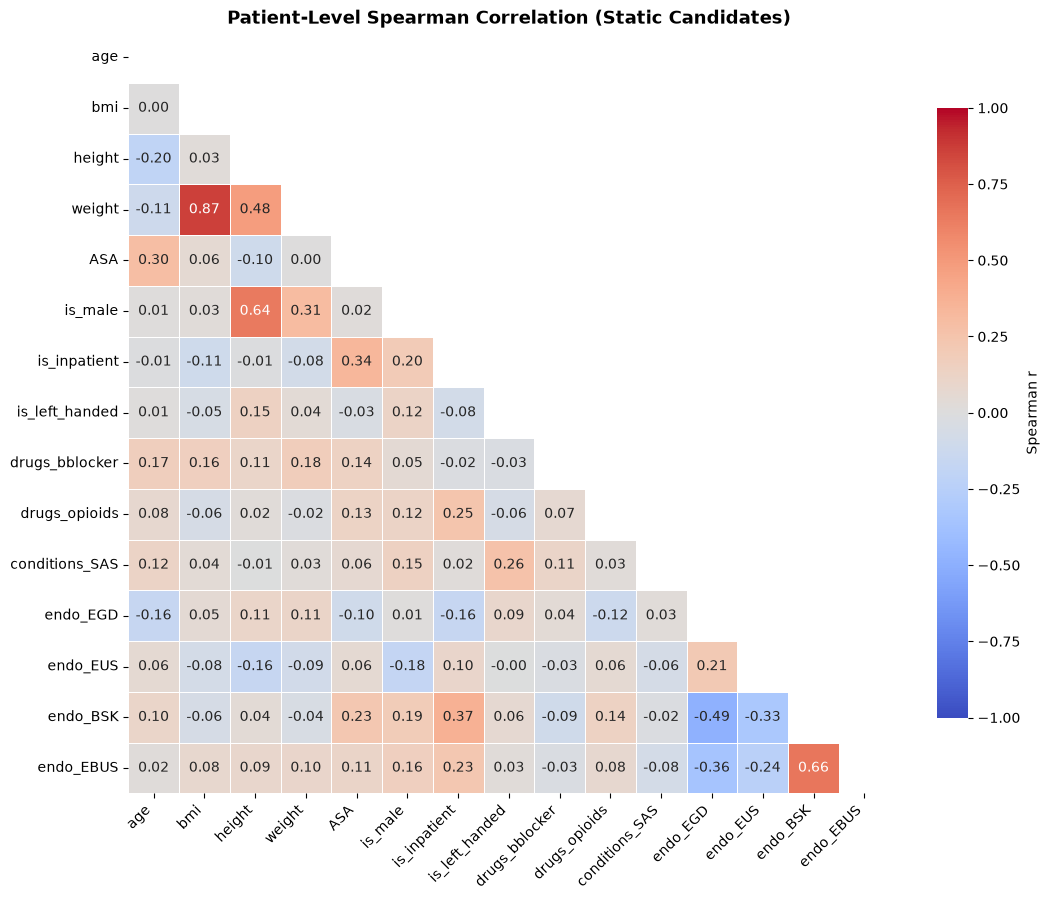

In [50]:
corr_matrix = patient_level_dev[static_candidates].corr(method="spearman")

# Mask the upper triangle so each pair appears once
mask = np.triu(np.ones_like(corr_matrix, dtype=bool))

plt.figure(figsize=(11, 9))
sns.heatmap(
    corr_matrix,
    mask=mask,
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    center=0,
    annot=True,
    fmt=".2f",
    square=True,
    linewidths=0.5,
    cbar_kws={"shrink": 0.8, "label": "Spearman r"},
)
plt.title("Patient-Level Spearman Correlation (Static Candidates)", fontsize=13, fontweight="bold")
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

We can see that weight, height, sex and bmi are logically strongly correlated. Different type of endoscopies too.  

In [51]:
def harrell_c_index(durations: np.ndarray, events: np.ndarray, scores: np.ndarray) -> float:
    """Compute Harrell's C-index handling right-censored observations."""
    mask = ~np.isnan(scores)
    t, e, x = durations[mask], events[mask], scores[mask]
    concordant = 0.0
    permissible = 0.0

    for i in range(len(t)):
        if e[i] == 1:
            # Compare against all episodes with strictly longer observed/censored duration
            valid = t > t[i]
            permissible += np.sum(valid)
            concordant += np.sum(x[valid] > x[i]) + 0.5 * np.sum(x[valid] == x[i])

    return concordant / permissible if permissible > 0 else 0.5

def logrank_pvalue(durations: np.ndarray, events: np.ndarray, group: np.ndarray) -> float:
    """Two-sample Mantel-Haenszel log-rank test p-value."""
    mask = ~np.isnan(group)
    t, e, g = durations[mask], events[mask], group[mask]
    unique_times = np.unique(t[e == 1])
    num, den = 0.0, 0.0

    for tj in unique_times:
        at_risk = t >= tj
        n1 = np.sum(at_risk & (g == 1))
        n0 = np.sum(at_risk & (g == 0))
        n = n1 + n0
        if n <= 1 or n1 == 0 or n0 == 0:
            continue
        d1 = np.sum((t == tj) & (e == 1) & (g == 1))
        d = np.sum((t == tj) & (e == 1))
        expected = d * (n1 / n)
        var = d * (n1 / n) * (n0 / n) * ((n - d) / (n - 1))
        num += (d1 - expected)
        den += var

    if den <= 0:
        return 1.0
    chi2_stat = (num ** 2) / den
    return float(stats.chi2.sf(chi2_stat, df=1))

results = []
t_dev = dev_encoded["duration_s"].to_numpy()
e_dev = dev_encoded["event_observed"].to_numpy()

for col in static_candidates:
    x = dev_encoded[col].to_numpy(dtype=float)
    c_raw = harrell_c_index(t_dev, e_dev, x)
    c_abs = max(c_raw, 1.0 - c_raw)
    direction = "+ (delays ROC)" if c_raw >= 0.5 else "- (faster ROC)"

    if dev_encoded[col].nunique() == 2:
        p_val = logrank_pvalue(t_dev, e_dev, x)
        med_1 = dev_encoded.loc[dev_encoded[col] == 1, "duration_s"].median()
        med_0 = dev_encoded.loc[dev_encoded[col] == 0, "duration_s"].median()
        med_diff = med_1 - med_0
    else:
        p_val = np.nan
        med_diff = np.nan

    results.append({
        "feature": col,
        "c_index": round(c_abs, 3),
        "direction": direction,
        "logrank_p": round(p_val, 4) if not np.isnan(p_val) else np.nan,
        "median_diff_s (1 - 0)": round(med_diff, 1) if not np.isnan(med_diff) else np.nan,
    })

static_ranking = pd.DataFrame(results).sort_values("logrank_p", ascending=True)
display(static_ranking)

,feature,c_index,direction,logrank_p,median_diff_s (1 - 0)
6,is_inpatient,0.556,+ (delays ROC),0.0000,68.0
13,endo_BSK,0.529,+ (delays ROC),0.0000,99.0
14,endo_EBUS,0.521,+ (delays ROC),0.0001,97.0
12,endo_EUS,0.551,+ (delays ROC),0.0064,88.0
10,conditions_SAS,0.514,- (faster ROC),0.0725,-73.0
9,drugs_opioids,0.513,+ (delays ROC),0.0738,42.0
11,endo_EGD,0.502,+ (delays ROC),0.2459,37.0
7,is_left_handed,0.505,+ (delays ROC),0.3715,49.0
8,drugs_bblocker,0.502,- (faster ROC),0.7415,-35.0
5,is_male,0.506,- (faster ROC),0.7942,-24.0


focus on logrank (https://en.wikipedia.org/wiki/Logrank_test) for binary variables and c_index (https://casrai.org/guides/harrells-c-index) for the rest 

-Harrell’s C-index quantifies the proportion of all usable (comparable) patient pairs in which the direction of the model’s predicted prognostic risk aligns with the observed order of survival times.

-The null hypothesis H0 is that it the shift is noise, and that the different groups have no effect. really small p value means that we can reject this H0 and that it is likely not noise 

Preliminary Results:
- provide weak c indices. 0.50 is random guessing, and most of them are around it. Considering logranks, we can reject noise assumptions for inpatient and endoscopies features

In [52]:
try:
    from sksurv.ensemble import RandomSurvivalForest
    from sksurv.util import Surv
    from sklearn.inspection import permutation_importance

    y_surv = Surv.from_arrays(event=dev_encoded["event_observed"].astype(bool),
                              time=dev_encoded["duration_s"])
    X_dev = dev_encoded[static_candidates].fillna(dev_encoded[static_candidates].median())

    rsf = RandomSurvivalForest(n_estimators=200, min_samples_leaf=10, random_state=42, n_jobs=-1)
    rsf.fit(X_dev, y_surv)

    perm = permutation_importance(rsf, X_dev, y_surv, n_repeats=15, random_state=42, n_jobs=-1)
    perm_df = pd.DataFrame({
        "feature": static_candidates,
        "perm_importance_mean": perm.importances_mean.round(4),
        "perm_importance_std": perm.importances_std.round(4),
    }).sort_values("perm_importance_mean", ascending=False)
    display(perm_df)
except ImportError:
    print("scikit-survival not installed; rely on Cell 2.2 C-index + log-rank ranking.")

,feature,perm_importance_mean,perm_importance_std
12,endo_EUS,0.0288,0.0042
2,height,0.0214,0.0040
6,is_inpatient,0.0196,0.0054
3,weight,0.0196,0.0042
1,bmi,0.0194,0.0026
0,age,0.0189,0.0026
13,endo_BSK,0.0062,0.0030
11,endo_EGD,0.0059,0.0023
8,drugs_bblocker,0.0049,0.0023
4,ASA,0.0035,0.0009


Interpretation: how much the results change across random shuffles 

Results: It suggests that the importance of bmi, weight, age and other features still have influence even if low c-index 

In [53]:
# 1. Drop obvious non-predictors and redundant body-size measures
update_static_selection("drugs_bblocker", "drop", "Lowest C-index (0.504), log-rank p=0.741, negligible RSF importance", tag="D")
update_static_selection("conditions_SAS", "drop", "Confounded direction (-48.5s faster ROC), noisy RSF importance (0.0013)", tag="D")
update_static_selection("height", "drop", "Lowest C-index (0.504) and collinear with bmi/is_male", tag="D")

update_static_selection("weight", "keep", "Collinear with bmi (which dominates in both C-index and RSF)", tag="M")

# 2. Promote core static predictors to 'K'
update_static_selection("is_inpatient", "keep", "Top univariate C-index (0.549, p=0.0001, +67s) + strong RSF importance", tag="K")
update_static_selection("endo_EUS", "keep", "Strong univariate C-index (0.535, +72s) + #4 RSF importance (0.0191)", tag="K")
update_static_selection("endo_BSK", "keep", "Significant log-rank (p<0.0001, +92s) + strong RSF importance", tag="K")
update_static_selection("endo_EBUS", "keep", "Significant log-rank (p<0.0001, +103.5s) + solid RSF importance", tag="K")
update_static_selection("bmi", "keep", "#1 RSF permutation importance (0.0335) + best body-size C-index (0.513)", tag="K")
update_static_selection("age", "keep", "#2 RSF permutation importance (0.0236); strong non-linear PK interaction", tag="K")
update_static_selection("is_left_handed", "drop", "From litterature: This information is particularly relevant for neurophysiological measurements, as hemispheric dominance may influence EEG patterns and electrode placement considerations, will need to anaylze correlation with EEGs", tag="K")

# 3. Explicitly tag borderline predictors as 'M' (kept in expanded static pool)
for feat, note in [
    ("is_male", "Modest univariate C-index (0.515) + RSF importance (0.0050)"),
    ("ASA", "Captures overall comorbidity burden; RSF importance (0.0045)"),
    ("endo_EGD", "Borderline log-rank (p=0.0548, +25.5s) + RSF importance (0.0049)"),
    ("drugs_opioids", "Clinically expected +39s delay; kept in M due to 8.8% prevalence but could be dropped, to debate"),
]:
    update_static_selection(feat, "keep", note, tag="M")

static_summary_df = pd.DataFrame.from_dict(
    static_audit_log, orient="index", columns=["status", "category_KMD", "rationale"]
).rename_axis("feature").reset_index()

print(f"Final Static -> Selected: {len(static_features_selected)} | Dropped: {len(static_features_dropped)}")
display(static_summary_df)

Final Static -> Selected: 11 | Dropped: 11


,feature,status,category_KMD,rationale
0,age,selected,K,#2 RSF permutation importance (0.0236); strong...
1,bmi,selected,K,#1 RSF permutation importance (0.0335) + best ...
2,height,dropped,D,Lowest C-index (0.504) and collinear with bmi/...
3,weight,selected,M,Collinear with bmi (which dominates in both C-...
4,ASA,selected,M,Captures overall comorbidity burden; RSF impor...
5,is_male,selected,M,Modest univariate C-index (0.515) + RSF import...
6,is_inpatient,selected,K,"Top univariate C-index (0.549, p=0.0001, +67s)..."
7,is_left_handed,dropped,K,From litterature: This information is particul...
8,drugs_bblocker,dropped,D,"Lowest C-index (0.504), log-rank p=0.741, negl..."
9,drugs_opioids,selected,M,Clinically expected +39s delay; kept in M due ...


In [54]:
print("Selected features:") 
print(static_features_selected)
print("Dropped features:")
print(static_features_dropped)

Selected features:
['age', 'bmi', 'weight', 'ASA', 'is_male', 'is_inpatient', 'drugs_opioids', 'endo_EGD', 'endo_EUS', 'endo_BSK', 'endo_EBUS']
Dropped features:
['ID', 'drugs_benzodiazepines', 'conditions_OHS', 'drugs_neuroleptics', 'conditions_oHE', 'conditions_CHF', 'drugs_antiepileptics', 'drugs_bblocker', 'conditions_SAS', 'height', 'is_left_handed']


## pEEG dataset Features Selection

In [55]:
# Reuse the exact patient-level fold assignment locked in during Section 1
id_to_fold = (
    static_episodes[["ID", "fold"]]
    .drop_duplicates("ID")
    .set_index("ID")["fold"]
    .to_dict()
)

# Inspect exact headers from the first file
sample_df = read_peeg(sorted(PEEG_DIR.glob("*_pEEG.csv"))[0]).iloc[:2]
peeg_all_cols = list(sample_df.columns)

print("=== 49 Columns in *_pEEG.csv (1-based index) ===")
for idx, col in enumerate(peeg_all_cols, start=1):
    print(f"{idx:2d}: {col}")

# Identify special columns by exact position (1-based: 1=Time, 46=Propofol, 47=MOAAS, 48=SOC, 49=Exam)
time_col = peeg_all_cols[0]
prop_col = peeg_all_cols[45]
moaas_col = peeg_all_cols[46]
soc_col = peeg_all_cols[47]
exam_col = peeg_all_cols[48]

# Initialize selection & audit tracking lists (matching Section 2)
peeg_features_dropped = [time_col, moaas_col, soc_col]
peeg_features_selected = [c for c in peeg_all_cols if c not in peeg_features_dropped]

peeg_audit_log = {
    time_col: ("dropped", "D", "Timestamp index only"),
    moaas_col: ("dropped", "D", "Clinical leakage: bedside sedation score unavailable in automated monitoring"),
    soc_col: ("dropped", "D", "Target variable: defines LOC/ROC and remaining_time_s"),
    **{c: ("selected", "M", "Candidate pEEG / vital / event feature") for c in peeg_features_selected},
}

def update_peeg_selection(feature: str, action: str, reason: str, tag: str = None):
    """Move a pEEG feature between selected and dropped lists and log the rationale."""
    if action == "drop":
        if feature in peeg_features_selected:
            peeg_features_selected.remove(feature)
        if feature not in peeg_features_dropped:
            peeg_features_dropped.append(feature)
        peeg_audit_log[feature] = ("dropped", tag or "D", reason)
    elif action == "keep":
        if feature not in peeg_features_selected:
            peeg_features_selected.append(feature)
        if feature in peeg_features_dropped:
            peeg_features_dropped.remove(feature)
        peeg_audit_log[feature] = ("selected", tag or "K", reason)

# Build unconscious time-series DataFrame (sedated_ts) + awake baseline medians for comparison
sedated_chunks = []
awake_chunks = []

for rec_str, rec_eps in episodes_df.groupby("recording_id"):
    patient_id = int(rec_str.split("-")[-1])
    if patient_id not in id_to_fold:
        continue

    df = read_peeg(PEEG_DIR / f"{rec_str}_pEEG.csv")
    dt = pd.to_datetime(df[time_col])
    t = (dt - dt.iloc[0]).dt.total_seconds().to_numpy(dtype=float)

    # Save awake rows (Consciousness state == 1) for physiological shift comparison
    awake_mask = (pd.to_numeric(df[soc_col], errors="coerce") == 1)
    if awake_mask.any():
        awake_sub = df.loc[awake_mask, peeg_features_selected].copy()
        awake_sub["ID"] = patient_id
        awake_sub["fold"] = id_to_fold[patient_id]
        awake_chunks.append(awake_sub)

    # Slice each eligible unconscious episode using exact t_start and t_end
    for ep in rec_eps.itertuples():
        ep_mask = (t >= ep.t_start) & (t < ep.t_end)
        if not np.any(ep_mask):
            continue

        chunk = df.loc[ep_mask, peeg_features_selected].copy()
        chunk["ID"] = patient_id
        chunk["recording_id"] = rec_str
        chunk["episode_num"] = ep.episode_num
        chunk["fold"] = id_to_fold[patient_id]
        chunk["remaining_time_s"] = ep.t_end - t[ep_mask]
        chunk["event_observed"] = int(ep.event_observed)
        sedated_chunks.append(chunk)

sedated_ts = pd.concat(sedated_chunks, ignore_index=True)
awake_ts = pd.concat(awake_chunks, ignore_index=True)

# Restrict strictly to development patients (Folds 0-3)
dev_sedated = sedated_ts[sedated_ts["fold"] != 4].copy()
dev_awake = awake_ts[awake_ts["fold"] != 4].copy()

print(f"\nDevelopment sedated rows (1 Hz): {len(dev_sedated):,} across {dev_sedated['ID'].nunique()} patients")
print(f"Starting Section 3 -> Selected: {len(peeg_features_selected)} | Dropped: {len(peeg_features_dropped)}")

=== 49 Columns in *_pEEG.csv (1-based index) ===
 1: Time
 2: abs_subdelta
 3: abs_delta1
 4: abs_delta2
 5: abs_theta
 6: abs_alpha
 7: abs_beta1
 8: abs_beta2
 9: abs_gamma
10: rel_subdelta
11: rel_delta1
12: rel_delta2
13: rel_theta
14: rel_alpha
15: rel_beta1
16: rel_beta2
17: rel_gamma
18: sync_subdelta
19: sync_delta1
20: sync_delta2
21: sync_theta
22: sync_alpha
23: sync_beta1
24: sync_beta2
25: sync_gamma
26: MF
27: SEF95
28: WSMF30
29: WSMF49
30: PE31
31: PE32
32: PE61
33: SFS
34: CFS
35: PFS
36: WSMF_Klimpel
37: MF_Jordan
38: SEF95_Jordan
39: WSMF30_16
40: WSMF49_16
41: WSMF_Klimpel_16
42: Intellivue/ECG_HR
43: Intellivue/PLETH_HR
44: Intellivue/RR
45: Intellivue/PLETH_SAT_O2
46: Propofol
47: MOAAS
48: SOC
49: Endoscopy

Development sedated rows (1 Hz): 151,023 across 153 patients
Starting Section 3 -> Selected: 46 | Dropped: 3


In [56]:
missing_audit = pd.DataFrame({
    "col_idx_1based": [peeg_all_cols.index(c) + 1 for c in peeg_features_selected],
    "feature": peeg_features_selected,
    "missing_pct_sedated": (dev_sedated[peeg_features_selected].isna().mean() * 100).round(2).values,
    "std_sedated": dev_sedated[peeg_features_selected].std(numeric_only=True).reindex(peeg_features_selected).round(4).values,
}).sort_values("missing_pct_sedated", ascending=False)

display(missing_audit)

,col_idx_1based,feature,missing_pct_sedated,std_sedated
35,37,MF_Jordan,14.95,3.3971
36,38,SEF95_Jordan,14.95,4.7057
39,41,WSMF_Klimpel_16,14.95,0.4986
37,39,WSMF30_16,14.95,0.7270
38,40,WSMF49_16,14.95,3.3801
25,27,SEF95,10.14,4.9108
27,29,WSMF49,10.14,3.4447
29,31,PE32,10.14,0.0460
26,28,WSMF30,10.14,0.7503
24,26,MF,10.14,3.5373


In [57]:
# Subsample every 10th second per episode for fast, balanced C-index computation
dev_grid = (
    dev_sedated
    .groupby(["ID", "episode_num"], group_keys=False)
    .apply(lambda g: g.iloc[::10])
    .reset_index(drop=True)
)

t_rem = dev_grid["remaining_time_s"].to_numpy(dtype=float)
e_obs = dev_grid["event_observed"].to_numpy(dtype=int)

# Precompute patient-level medians in awake vs sedated states
med_awake = dev_awake.groupby("ID")[peeg_features_selected].median().median()
med_sedated = dev_sedated.groupby("ID")[peeg_features_selected].median().median()

peeg_results = []
for col in peeg_features_selected:
    x = pd.to_numeric(dev_grid[col], errors="coerce").to_numpy(dtype=float)
    c_raw = harrell_c_index(t_rem, e_obs, x)
    c_abs = max(c_raw, 1.0 - c_raw)
    direction = "+ (higher = longer to ROC)" if c_raw >= 0.5 else "- (higher = closer to ROC)"

    peeg_results.append({
        "col_idx": peeg_all_cols.index(col) + 1,
        "feature": col,
        "c_index": round(c_abs, 3),
        "direction": direction,
        "missing_pct": round(dev_sedated[col].isna().mean() * 100, 1),
        "median_sedated": round(float(med_sedated[col]), 3),
        "median_awake": round(float(med_awake[col]), 3),
    })

peeg_ranking = pd.DataFrame(peeg_results).sort_values("c_index", ascending=False)
display(peeg_ranking)

/tmp/ipykernel_4894/2969174114.py:5: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(lambda g: g.iloc[::10])


,col_idx,feature,c_index,direction,missing_pct,median_sedated,median_awake
36,38,SEF95_Jordan,0.587,- (higher = closer to ROC),14.9,16.266,19.592
25,27,SEF95,0.584,- (higher = closer to ROC),10.1,16.479,19.714
0,2,abs_subdelta,0.579,+ (higher = longer to ROC),6.8,2.782,2.822
39,41,WSMF_Klimpel_16,0.577,- (higher = closer to ROC),14.9,13.489,14.038
14,16,rel_beta2,0.575,- (higher = closer to ROC),1.3,-5.229,-4.628
3,5,abs_theta,0.571,+ (higher = longer to ROC),1.3,-0.136,-0.167
34,36,WSMF_Klimpel,0.571,- (higher = closer to ROC),10.1,13.550,14.099
29,31,PE32,0.569,- (higher = closer to ROC),10.1,1.863,1.904
13,15,rel_beta1,0.566,- (higher = closer to ROC),1.3,-4.156,-3.847
24,26,MF,0.562,- (higher = closer to ROC),10.1,1.770,2.014


In [58]:
# Compute Spearman correlation on the 10s development grid
corr_peeg = dev_grid[peeg_features_selected].corr(method="spearman")
c_lookup = peeg_ranking.set_index("feature")["c_index"].to_dict()

redundant_pairs = []
cols = peeg_features_selected
for i in range(len(cols)):
    for j in range(i + 1, len(cols)):
        r = corr_peeg.iloc[i, j]
        if abs(r) >= 0.85:
            f1, f2 = cols[i], cols[j]
            redundant_pairs.append({
                "feature_A": f1,
                "C_idx_A": c_lookup[f1],
                "feature_B": f2,
                "C_idx_B": c_lookup[f2],
                "spearman_r": round(float(r), 3),
            })

redundant_df = pd.DataFrame(redundant_pairs).sort_values("spearman_r", key=abs, ascending=False)
print(f"Found {len(redundant_df)} highly collinear pairs (|Spearman r| >= 0.85):")
display(redundant_df)

Found 29 highly collinear pairs (|Spearman r| >= 0.85):


,feature_A,C_idx_A,feature_B,C_idx_B,spearman_r
18,WSMF49,0.544,WSMF49_16,0.549,0.971
11,WSMF30,0.556,WSMF30_16,0.561,0.962
25,WSMF_Klimpel,0.571,WSMF_Klimpel_16,0.577,0.955
26,WSMF30_16,0.561,WSMF49_16,0.549,0.949
8,SEF95,0.584,SEF95_Jordan,0.587,0.946
9,WSMF30,0.556,WSMF49,0.544,0.946
15,WSMF49,0.544,PE61,0.536,0.933
21,PE61,0.536,PFS,0.518,0.930
27,WSMF30_16,0.561,WSMF_Klimpel_16,0.577,0.927
17,WSMF49,0.544,WSMF30_16,0.561,0.925


We can see that as suspected, many features are strongly correlated. Between those collinear features, we suggest keeping the one with the largest c-index and features with the least missing values. 

### pEEG features selection proposition 

In [59]:
# 1. Drop collinear duplicates (16s windows, redundant PE orders, redundant HR, weak/noisy bands)
collinear_drops = [
    #("SEF95_Jordan", "Collinear with SEF95 (r=0.946); nearly identical C-index (0.587 vs 0.584) with higher missingness (14.9% vs 10.1%)"), #TO DEBATE Since highly collinear with SEF95
    #("WSMF_Klimpel_16", "Collinear with WSMF_Klimpel (r=0.955); higher missingness (14.9% vs 10.1%)"),
    #("WSMF30_16", "Collinear with WSMF30 (r=0.962) and WSMF_Klimpel (r=0.927)"),
    ("WSMF49_16", "Collinear with WSMF49 (r=0.971) and WSMF30_16 (r=0.949)"),
    ("WSMF49", "Collinear with WSMF30 (r=0.946) and lower C-index (0.544 vs 0.556)"),
    ("WSMF30", "Collinear with WSMF_Klimpel (r=0.915) and lower C-index (0.556 vs 0.571)"),
    ("MF_Jordan", "Collinear with MF (r=0.907); higher missingness (14.9% vs 10.1%)"),
    #("PE31", "Collinear with PE32 (r=0.861) and lower C-index (0.540 vs 0.569)"),
    ("PE61", "Collinear with PE32/WSMF49 (r=0.933) and lower C-index (0.536)"),
    ("PFS", "Collinear with PE61/WSMF49 (r=0.930) and weak C-index (0.518)"),
    ("Intellivue/PLETH_HR", "Collinear with Intellivue/ECG_HR (r=0.920) and slightly lower C-index (0.515 vs 0.519)"),
    #("abs_delta2", "Collinear with abs_delta1 (r=0.871) and slightly lower C-index (0.553 vs 0.556)"),
    #("rel_alpha", "Collinear with rel_beta1 (r=0.910) and lower C-index (0.537 vs 0.566)"), #Not sure whether to keep or not since alpha important in litterature
    ("rel_theta", "Collinear with rel_alpha (r=0.905) and lower C-index (0.525)"),
]
for feat, reason in collinear_drops:
    update_peeg_selection(feat, "drop", reason, tag="D")

# 2. Drop near-random connectivity/vital metrics (C-index <= 0.517 and redundant)
noise_drops = [
    ("Intellivue/RR", "Near-random C-index (0.504)"),
    ("sync_beta1", "Near-random C-index (0.504)"),
    ("rel_subdelta", "Near-random C-index (0.504) and 6.8% missingness"),
    ("sync_delta2", "Weak C-index (0.510)"),
    ("sync_delta1", "Weak C-index (0.512)"),
    ("sync_beta2", "Weak C-index (0.514)"),
    ("sync_subdelta", "Weak C-index (0.515) and 8.1% missingness"),
    ("sync_gamma", "Weak C-index (0.516)"),
    ("CFS", "Weak C-index (0.517) and 10.1% missingness"),
    ("sync_theta", "Weak C-index (0.517)"),
]
for feat, reason in noise_drops:
    update_peeg_selection(feat, "drop", reason, tag="D")

# 3. non-redundant pEEG predictors 
core_keeps = [
    ("SEF95", "Top non-redundant spectral edge feature (C-index 0.584, 10.1% missing, strong awake shift 19.7->16.5 Hz)"),
    ("abs_subdelta", "Top slow-wave power predictor (C-index 0.579, delays ROC)"),
    ("rel_beta2", "Strong fast-band predictor (C-index 0.575) with ultra-low missingness (1.3%)"),
    ("abs_theta", "Strong theta power predictor (C-index 0.571, 1.3% missing)"),
    ("WSMF_Klimpel", "Best weighted spectral median frequency variant (C-index 0.571, 10.1% missing)"),
    ("PE32", "Top Permutation Entropy variant (C-index 0.569, clear awake shift)"),
    ("rel_beta1", "Strong beta1 predictor (C-index 0.566, 1.3% missing)"),
    ("MF", "Best median frequency variant (C-index 0.562, 10.1% missing)"),
    ("rel_gamma", "Strong gamma shift (C-index 0.560, 1.3% missing)"),
    ("abs_delta1", "Best delta power band (C-index 0.556, 3.0% missing)"),
    ("Endoscopy", "Active procedure indicator (C-index 0.541, 0% missing)"),
    ("Propofol", "Essential bolus log (0% missing) for cumulative dose & decay feature engineering"),
]
for feat, reason in core_keeps:
    update_peeg_selection(feat, "keep", reason, tag="K")

# Remaining features stay tagged as 'M' (e.g., rel_delta1/2, abs_alpha, abs_beta1/2, abs_gamma, SFS, sync_alpha, ECG_HR, SpO2)
peeg_summary_df = pd.DataFrame.from_dict(
    peeg_audit_log, orient="index", columns=["status", "category_KMD", "rationale"]
).rename_axis("feature").reset_index()

print(f"Final pEEG -> Selected: {len(peeg_features_selected)} | Dropped: {len(peeg_features_dropped)}")
display(peeg_summary_df)

Final pEEG -> Selected: 28 | Dropped: 21


,feature,status,category_KMD,rationale
0,Time,dropped,D,Timestamp index only
1,MOAAS,dropped,D,Clinical leakage: bedside sedation score unava...
2,SOC,dropped,D,Target variable: defines LOC/ROC and remaining...
3,abs_subdelta,selected,K,"Top slow-wave power predictor (C-index 0.579, ..."
4,abs_delta1,selected,K,"Best delta power band (C-index 0.556, 3.0% mis..."
5,abs_delta2,selected,M,Candidate pEEG / vital / event feature
6,abs_theta,selected,K,"Strong theta power predictor (C-index 0.571, 1..."
7,abs_alpha,selected,M,Candidate pEEG / vital / event feature
8,abs_beta1,selected,M,Candidate pEEG / vital / event feature
9,abs_beta2,selected,M,Candidate pEEG / vital / event feature


Not sure about dropping some of the alphas even if collinear with other features, since in litterature analyis alpha low frequencies were marked as an important feature to predict   consciousness.


## AI Usage

I used Gemini while developing this notebook, notably for:

- **Code generation, debugging, and refactoring:** Writing the episode extraction pipeline, structuring feature-selection audit logs and methods generation.
- **Temporal & survival data best practices** 
- **Feature selection metrics & interpretation:** Choosing survival evaluation criteria (Harrell's C-index, Mantel–Haenszel log-rank $p$-values, and Random Survival Forest permutation importance), auditing artifact missingness, and dropping collinear EEG features via Spearman correlation.